# Example 12: Unsupervised learning

In this example, we will use KAN for unsupervised learning. Instead of trying to figure out how a target variable $y$ depends on input variables, we treat all variables on the equal footing (as input variables). Below we contruct a synthetic dataset where we have six variables $x_1, x_2, x_3, x_4, x_5, x_6$. $(x_1, x_2, x_3)$ are dependent such that $x_3={\rm exp}({\rm sin}(\pi x_1)+x_2^2)$; $(x_4,x_5)$ are dependent such that $x_5=x_4^3$. And $x_6$ is independent of all other variables. Can we use KANs to discover these dependent groups?

The idea is that we treat the problem as a classification problem. The dataset that satisfies these interdependent relations are 'positive' samples, while corrupted samples (by random permutation of features across samples) are 'negative' samples. We want to train a KAN to output 1 when it is a positive sample, and output 0 when it is a negative sample. We set the last layer activation to be Gaussian, so positive samples will have zero activation in the second to last layer, while negtive samples will have non-zero activation in the second to last layer. We can then define the relation implicitly as $g=0$ where $g$ is the activation in the second to last layer.

Intialize model and create dataset

In [1]:
import copy

import torch
from xkan import KANNetwork, fit
from xkan.symbolic import fix_symbolic
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

seed = 1

model = KANNetwork([6, 1, 1], grid=3, k=3, seed=seed, device=device)

# create dataset


def create_dataset(train_num=500, test_num=500):
    
    def generate_contrastive(x):
        # positive samples
        batch = x.shape[0]
        x[:,2] = torch.exp(torch.sin(torch.pi*x[:,0])+x[:,1]**2)
        x[:,3] = x[:,4]**3

        # negative samples
        def corrupt(tensor):
            y = copy.deepcopy(tensor)
            for i in range(y.shape[1]):
                y[:,i] = y[:,i][torch.randperm(y.shape[0])]
            return y

        x_cor = corrupt(x)
        x = torch.cat([x, x_cor], dim=0)
        y = torch.cat([torch.ones(batch,), torch.zeros(batch,)], dim=0)[:,None]
        return x, y
        
    x = torch.rand(train_num, 6) * 2 - 1
    x_train, y_train = generate_contrastive(x)
    
    x = torch.rand(test_num, 6) * 2 - 1
    x_test, y_test = generate_contrastive(x)
    
    # inputs under 'x', labels under 'y'
    train = {'x': x_train.to(device), 'y': y_train.to(device)}
    test = {'x': x_test.to(device), 'y': y_test.to(device)}
    return train, test

# the network's seed only seeds its own initialisation: seed the draws of the dataset too
torch.manual_seed(seed)
train, test = create_dataset()

cuda


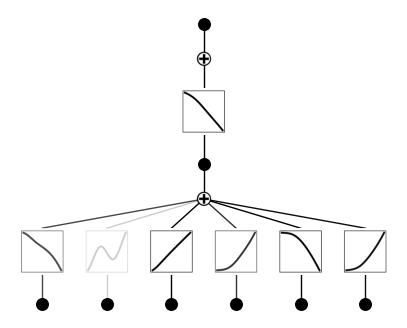

In [2]:
plot(model, train['x'], beta=10);

In [3]:
# set the (1,0,0) activation to be gausssian
#fix_symbolic(model, 1, 0, 0, lambda x: torch.exp(-x**2/10), fit=False)
fix_symbolic(model, 1, 0, 0, 'gaussian', fit=False)

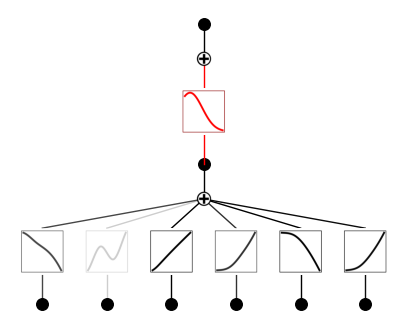

In [4]:
plot(model, train['x'], beta=10);

In [5]:
history = fit(model, train, test, steps=50, lamb=0.002, lamb_entropy=10.0, lamb_coef=1.0)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.1559455826772621 test RMSE 0.14810177205445166


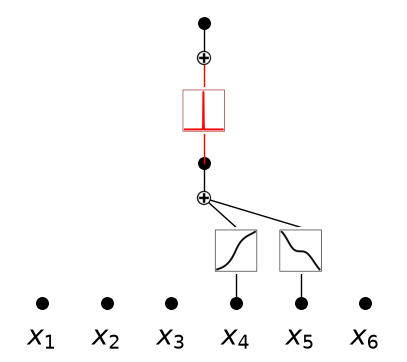

In [6]:
plot(model, train['x'], in_vars=[r'$x_{}$'.format(i) for i in range(1,7)]);

This gives the dependence among $(x_4,x_5)$. Another random seed can give dependence among $(x_1,x_2,x_3)$.